# Module 6 Assignment - Transfer Learning Starter Code
---
<div class="alert alert-block alert-success" style="color:black;">
<b>To Begin:</b> Use this <b>Module_6_Transfer_Learning_Starter_Code.ipynb</b> file to complete the assignment.. Then, you may create your own .ipynb file or .py file to complete this assignment.
<br><br>
<b>When Finished:</b> When you have completed your work, submit the work as a <b>.ipynb file</b> or a <b>.py</b> file to BrightSpace.
</div>

<div class="alert alert-block alert-info" style="color:black;">
Look for the header <b>Start of Rubric Graded Items</b> to work on your assignment if you are going to submit this file as the work submission.
</div>

<div class="alert alert-block alert-danger" style="color:black;">
<b>GPU/CUDA/Memory Warnings/Errors:</b> You may receive some errors referencing that GPUs will not be used, CUDA could not be found, or free system memory allocation errors. These and a few others, are standard errors that can be ignored here as they are environment based.<br><br>
<b>Example messages:</b>
    <ul>
        <li>Could not find cuda drivers on your machine, GPU will not be used.</li>
        <li>Please check linkage and avoid linking the same target more than once.</li>
        <li>E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)</li>
        <li>Allocation of ######## exceeds 10% of free system memory</li>
    </ul>
</div>

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

2026-10-28 23:10:11.946471: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/home/ubuntu/.local/lib/python3.13/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


TensorFlow version: 2.20.0


## Start of Graded Rubric Item

### TODO: Analyze the dataset.

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_train = y_train.squeeze()
y_test  = y_test.squeeze()

num_classes = 10

print("Train images:", x_train.shape, "Train labels:", y_train.shape)
print("Test images: ", x_test.shape,  "Test labels: ", y_test.shape)

# CIFAR-10 image size and number of classes (for rubric)
image_height, image_width, channels = x_train.shape[1:]
print(f"Image size: {image_height}x{image_width}x{channels}")
print(f"Number of classes: {num_classes}")

# Create validation split from training data
val_size = 10000
x_val = x_train[-val_size:]
y_val = y_train[-val_size:]
x_train = x_train[:-val_size]
y_train = y_train[:-val_size]

print("Train:", x_train.shape, "Val:", x_val.shape, "Test:", x_test.shape)

# Optional: use a subset of training data for faster experimentation
# x_train = x_train[:20000]
# y_train = y_train[:20000]
# print("Using subset of training data:", x_train.shape[0])

Train images: (50000, 32, 32, 3) Train labels: (50000,)
Test images:  (10000, 32, 32, 3) Test labels:  (10000,)
Image size: 32x32x3
Number of classes: 10
Train: (40000, 32, 32, 3) Val: (10000, 32, 32, 3) Test: (10000, 32, 32, 3)


### TODO: Apply data augmentation 

In [3]:
IMG_SIZE = 96  # we will resize 32x32 -> 96x96 for MobileNetV2
BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

def preprocess(image, label):
    image = tf.cast(image, tf.float32)
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = preprocess_input(image)  # MobileNetV2 preprocessing
    return image, label

def augment(image, label):
    image = tf.image.random_flip_left_right(image)
    # students can add more augmentation here (random crop, rotation, etc.)
    return image, label

train_ds = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(10000)
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .map(augment, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices((x_val, y_val))
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    tf.data.Dataset.from_tensor_slices((x_test, y_test))
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

2026-10-28 23:13:09.608804: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


### TODO: Configure selected pre-selected model.

In [5]:
# Example of MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet",
)

# TODO: Freeze the base model (feature extractor stage)
base_model.trainable = False

# TODO: Replace the final layers
# Update control of training behavior of frozen layers
inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

model = keras.Model(inputs, outputs)



print("\nTransfer Learning Model (MobileNetV2 base):")
model.summary()


Transfer Learning Model (MobileNetV2 base):


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### TODO: Compile the model for evaluation 

In [6]:
# Choose optimizer, loss, metrics

initial_lr = 0.001 # TODO: Determine learning rate
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=initial_lr),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],  # accuracy + loss (from compile/evaluate)
)


epochs_feature = 5
# Hint: Use model.fit() with train_ds and val_ds

history_feat = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs_feature,
)


Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 182s 284ms/step - accuracy: 0.7799 - loss: 0.6551 - val_accuracy: 0.8508 - val_loss: 0.4337
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 170s 272ms/step - accuracy: 0.8424 - loss: 0.4596 - val_accuracy: 0.8591 - val_loss: 0.4037
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 170s 272ms/step - accuracy: 0.8505 - loss: 0.4342 - val_accuracy: 0.8628 - val_loss: 0.4028
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 214s 291ms/step - accuracy: 0.8581 - loss: 0.4126 - val_accuracy: 0.8661 - val_loss: 0.3900
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 199s 319ms/step - accuracy: 0.8614 - loss: 0.4046 - val_accuracy: 0.8591 - val_loss: 0.4008


### TODO: Configuration of selected pre-trained model, training pre-trained model, evaluate transfer learning behavior

In [7]:
# Fine-tuning of base model layers
fine_tune = True
history_fine = None

if fine_tune:
    # TODO: Unfreeze the base model
    base_model.trainable = True

    
    # TODO: Freeze the bottom N layers; fine-tune the rest
    fine_tune_at = 100 # students can adjust based on rubric reasoning

    for layer in base_model.layers[:fine_tune_at]:
        layer.trainable = False

    # TODO: Recompile model with a lower learning_rate
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-5),  # Much lower LR for delicate fine-tuning
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )


    fine_epochs = 5 #Determine fine_epochs value
    total_epochs = epochs_feature + fine_epochs

    history_fine = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=total_epochs,
        initial_epoch=history_feat.epoch[-1] + 1,
    )

Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 301s 463ms/step - accuracy: 0.7991 - loss: 0.6630 - val_accuracy: 0.8643 - val_loss: 0.4301
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 295s 472ms/step - accuracy: 0.8570 - loss: 0.4472 - val_accuracy: 0.8814 - val_loss: 0.3799
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 288s 460ms/step - accuracy: 0.8780 - loss: 0.3703 - val_accuracy: 0.8894 - val_loss: 0.3529
Epoch 9/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 289s 463ms/step - accuracy: 0.8944 - loss: 0.3150 - val_accuracy: 0.8953 - val_loss: 0.3402
Epoch 10/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 281s 449ms/step - accuracy: 0.9038 - loss: 0.2798 - val_accuracy: 0.8950 - val_loss: 0.3304


<div class="alert alert-block alert-info" style="color:black;">
Below <b>plot_history() method</b> is used to compare loss and accuracy in terms of epochs
</div>

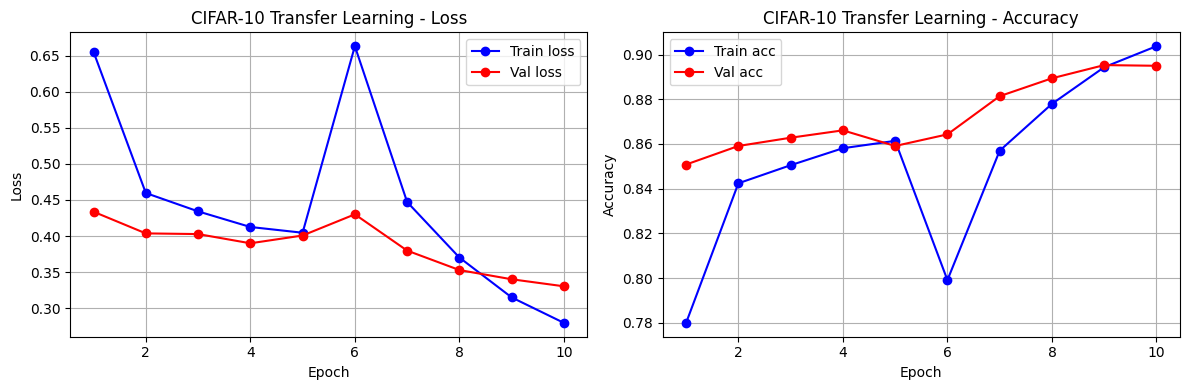

In [8]:
def plot_history(history1, history2=None, title_prefix="CIFAR-10 Transfer Learning"):
    acc = history1.history["accuracy"]
    val_acc = history1.history["val_accuracy"]
    loss = history1.history["loss"]
    val_loss = history1.history["val_loss"]

    epochs_acc = list(range(1, len(acc) + 1))

    if history2 is not None:
        acc += history2.history["accuracy"]
        val_acc += history2.history["val_accuracy"]
        loss += history2.history["loss"]
        val_loss += history2.history["val_loss"]
        epochs_acc = list(range(1, len(acc) + 1))

    plt.figure(figsize=(12, 4))

    # Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs_acc, loss, "b-o", label="Train loss")
    plt.plot(epochs_acc, val_loss, "r-o", label="Val loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{title_prefix} - Loss")
    plt.legend()
    plt.grid(True)

    # Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs_acc, acc, "b-o", label="Train acc")
    plt.plot(epochs_acc, val_acc, "r-o", label="Val acc")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(f"{title_prefix} - Accuracy")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.savefig("cifar10_transfer_learning_curves.png", dpi=150)
    plt.show()

plot_history(history_feat, history_fine if fine_tune else None)

### TODO: Evaluate test set

In [9]:
# ---------------------------------------------------------
# 7. Evaluate on test set (accuracy + loss)
# ---------------------------------------------------------
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss:     {test_loss:.4f}")

Test accuracy: 0.8926
Test loss:     0.3457


### TODO: Evaluate moel's performance and explain observed results

#### Markdown Cell for above TODO